# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Isi Nama Kalian | Isi NRP Kalian |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

# kneed bersifat opsional; jika tidak terpasang, dipakai fungsi pengganti di bagian 3.2
try:
    from kneed import KneeLocator
    HAS_KNEED = True
except ImportError:
    HAS_KNEED = False

sns.set_style('whitegrid')
RANDOM_STATE = 42
print('Library berhasil diimpor. kneed tersedia:', HAS_KNEED)

Library berhasil diimpor. kneed tersedia: False


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.

df = pd.read_csv('Live.csv')

print('Jumlah baris dan kolom:', df.shape)
print('\nTipe data tiap kolom:')
print(df.dtypes)

print('\nCuplikan data:')
display(df.head())

print('Statistik deskriptif:')
display(df.describe().T)

print('Jumlah missing value per kolom:')
print(df.isna().sum())

kolom_kosong = df.columns[df.isna().all()].tolist()
print('\nKolom yang seluruhnya kosong:', kolom_kosong)

print('\nstatus_id unik semua baris?', df['status_id'].is_unique)
print('Baris duplikat (seluruh kolom, termasuk status_id):', df.duplicated().sum())
print('Baris duplikat (status_id diabaikan)              :', df.drop(columns='status_id').duplicated().sum())

Jumlah baris dan kolom: (7050, 16)

Tipe data tiap kolom:
status_id             int64
status_type             str
status_published        str
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64
dtype: object

Cuplikan data:


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


Jumlah missing value per kolom:
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']

status_id unik semua baris? True
Baris duplikat (seluruh kolom, termasuk status_id): 0
Baris duplikat (status_id diabaikan)              : 54


,skewness,% nol,median,rata-rata,persentil 99,maksimum
num_reactions,3.74,1.72,59.5,230.12,2306.06,4710
num_comments,9.03,30.06,4.0,224.36,4338.04,20990
num_shares,7.10,55.48,0.0,40.02,607.00,3424
num_likes,3.92,1.79,58.0,215.04,2297.00,4710
num_loves,6.00,60.00,0.0,12.73,198.00,657
num_wows,18.25,75.29,0.0,1.29,16.00,278
num_hahas,20.31,83.91,0.0,0.70,12.00,157
num_sads,17.58,91.39,0.0,0.24,5.00,51
num_angrys,19.51,94.00,0.0,0.11,3.00,31


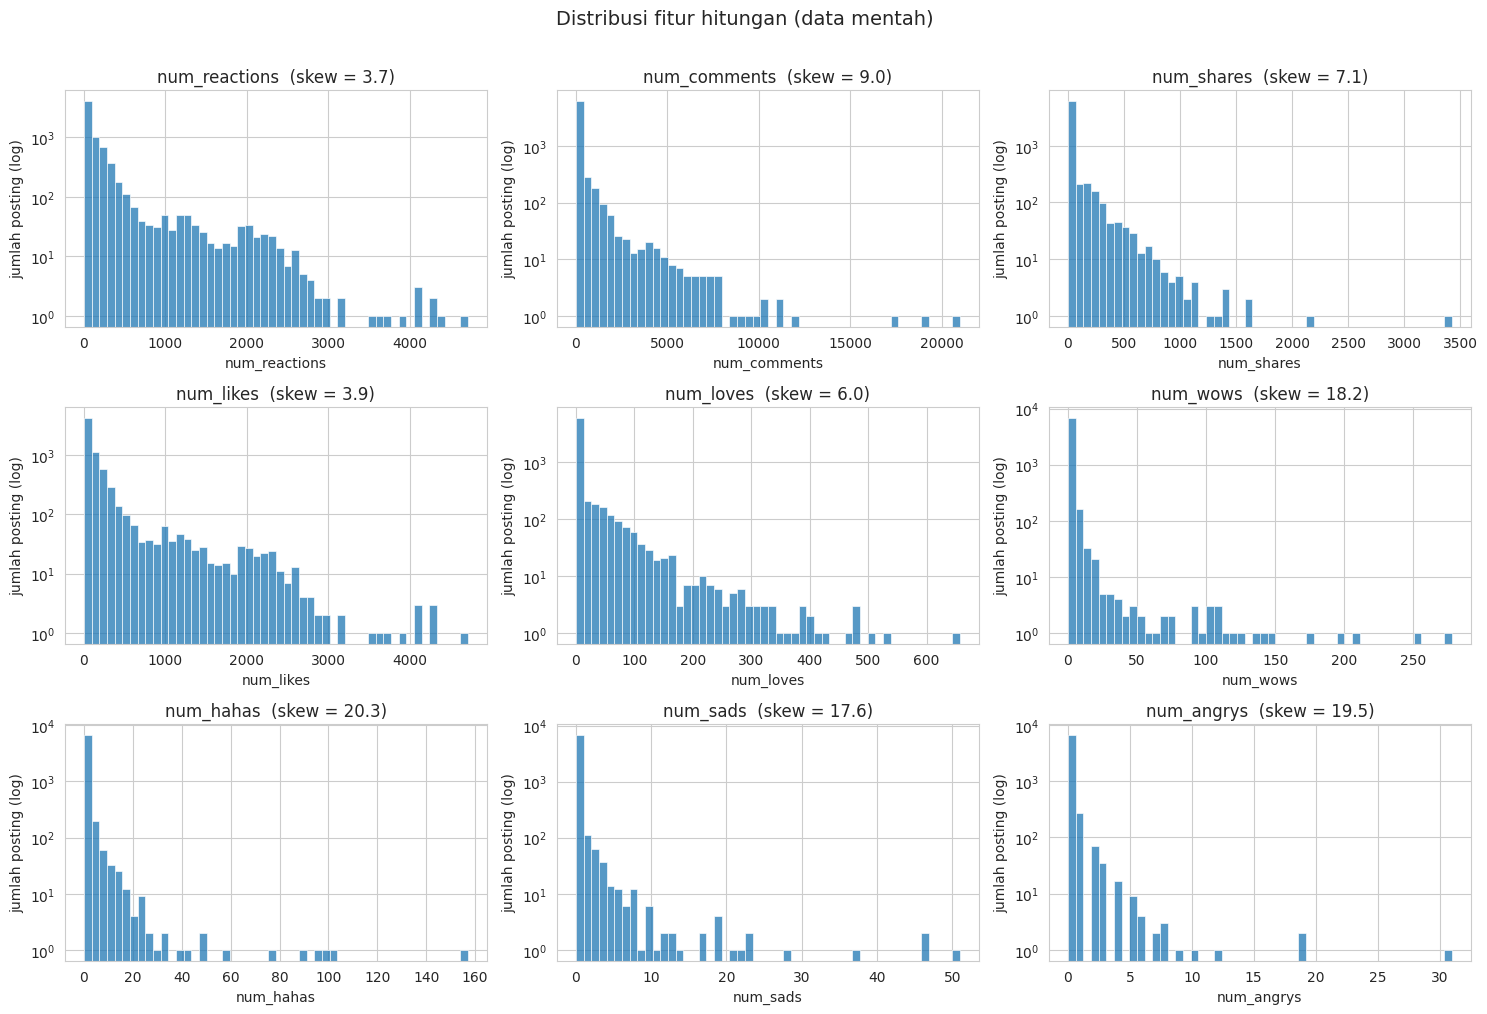

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.

count_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes',
              'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), count_cols):
    sns.histplot(df[c], bins=50, ax=ax)
    ax.set_yscale('log')   # skala log pada sumbu-y agar ekor panjang tetap terlihat
    ax.set_title(f'{c}  (skew = {df[c].skew():.1f})')
    ax.set_ylabel('jumlah posting (log)')
plt.suptitle('Distribusi fitur hitungan (data mentah)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

ringkasan = pd.DataFrame({
    'skewness': df[count_cols].skew(),
    '% nol': (df[count_cols] == 0).mean() * 100,
    'median': df[count_cols].median(),
    'rata-rata': df[count_cols].mean(),
    'persentil 99': df[count_cols].quantile(0.99),
    'maksimum': df[count_cols].max(),
}).round(2)
display(ringkasan)

Baris dengan num_reactions == likes + emoji: 99.87% (7041 dari 7050)
Selisih maksimum (mutlak): 4


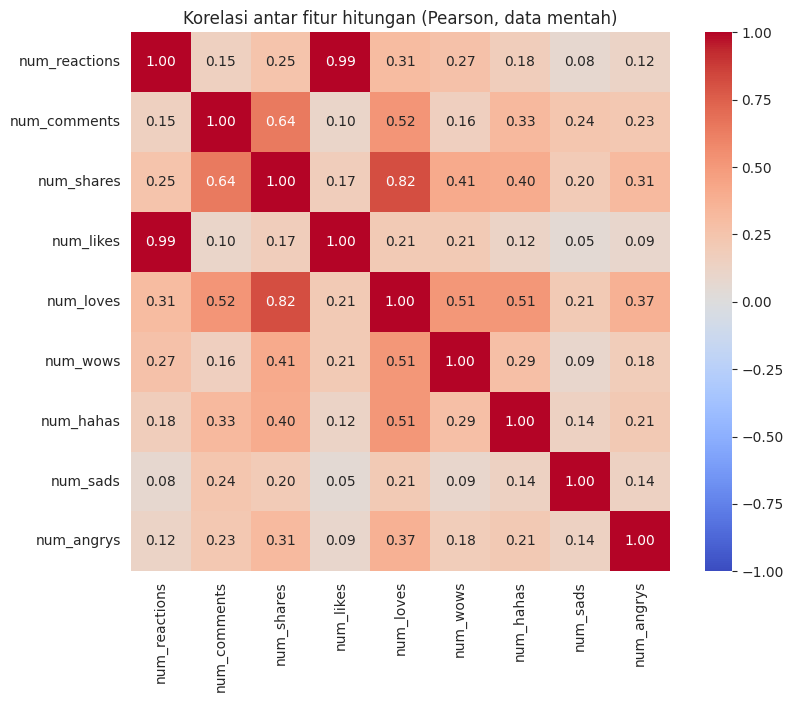

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.

plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Korelasi antar fitur hitungan (Pearson, data mentah)')
plt.show()

# Hubungan definisi: num_reactions = num_likes + seluruh reaksi emoji?
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
selisih = df['num_reactions'] - df[['num_likes'] + emoji_cols].sum(axis=1)
print(f'Baris dengan num_reactions == likes + emoji: {(selisih == 0).mean()*100:.2f}% ({(selisih == 0).sum()} dari {len(df)})')
print('Selisih maksimum (mutlak):', selisih.abs().max())

,jumlah_posting,% posting dengan emoji
year,,
2012,589,0.0
2013,500,0.0
2014,233,0.0
2015,337,0.0
2016,588,68.0
2017,2253,54.2
2018,2550,57.8


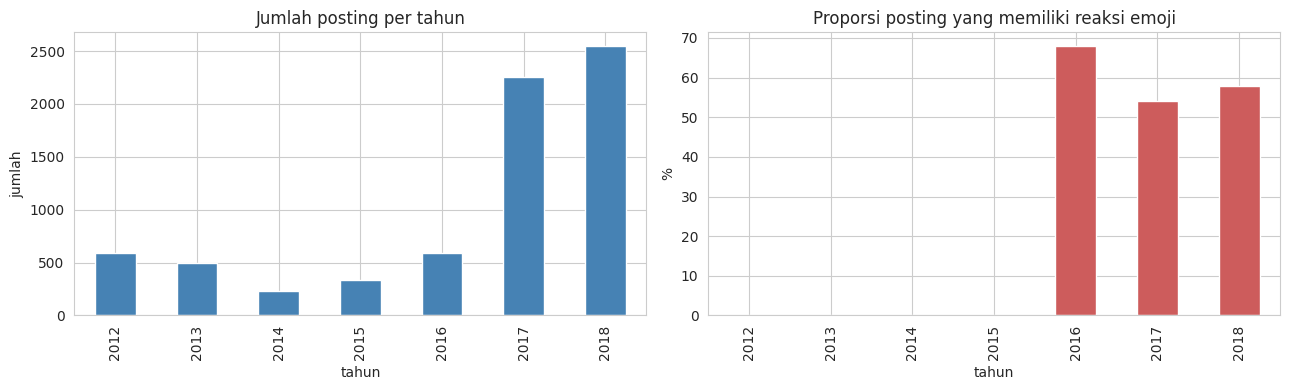

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.

df['status_published'] = pd.to_datetime(df['status_published'], format='%m/%d/%Y %H:%M')
df['year'] = df['status_published'].dt.year
df['has_emoji'] = df[emoji_cols].sum(axis=1) > 0

per_tahun = df.groupby('year').agg(jumlah_posting=('status_id', 'size'),
                                    proporsi_ada_emoji=('has_emoji', 'mean'))
per_tahun['proporsi_ada_emoji'] = (per_tahun['proporsi_ada_emoji'] * 100).round(1)
per_tahun = per_tahun.rename(columns={'proporsi_ada_emoji': '% posting dengan emoji'})
display(per_tahun)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_tahun['jumlah_posting'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Jumlah posting per tahun'); axes[0].set_xlabel('tahun'); axes[0].set_ylabel('jumlah')
per_tahun['% posting dengan emoji'].plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('Proporsi posting yang memiliki reaksi emoji'); axes[1].set_xlabel('tahun'); axes[1].set_ylabel('%')
plt.tight_layout()
plt.show()

,num_likes,num_comments,num_shares
status_type,,,
photo,34.0,2.0,0.0
video,117.0,39.0,12.0
status,117.0,10.0,0.0
link,48.0,1.0,0.0


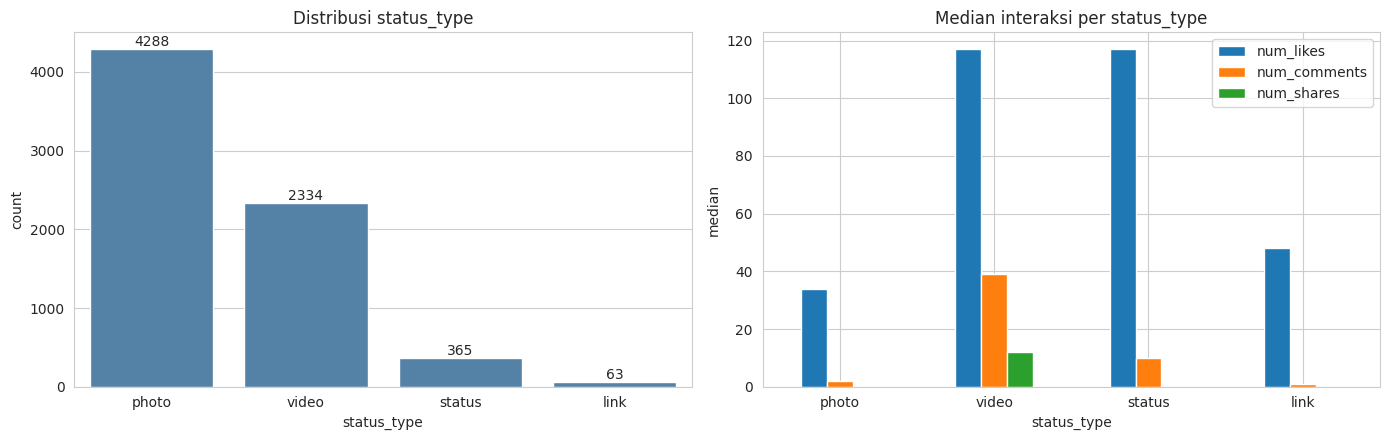

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

order = df['status_type'].value_counts().index
sns.countplot(data=df, x='status_type', order=order, ax=axes[0], color='steelblue')
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')
axes[0].set_title('Distribusi status_type')

med = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median().loc[order]
med.plot(kind='bar', ax=axes[1])
axes[1].set_title('Median interaksi per status_type')
axes[1].set_ylabel('median'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

display(med)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

,num_likes,num_comments,num_shares,num_loves
year,,,,
2012,19.0,5.0,0.0,0.0
2013,55.0,3.0,0.0,0.0
2014,437.0,10.0,1.0,0.0
2015,1566.0,12.0,1.0,0.0
2016,139.0,6.0,0.0,1.0
2017,41.0,3.0,0.0,0.0
2018,54.5,2.5,1.0,1.0


,% nol num_comments,% nol num_shares,% nol num_loves
status_type,,,
photo,32.1,67.9,68.6
video,28.3,31.7,44.0
status,14.8,62.5,58.9
link,47.6,50.8,77.8


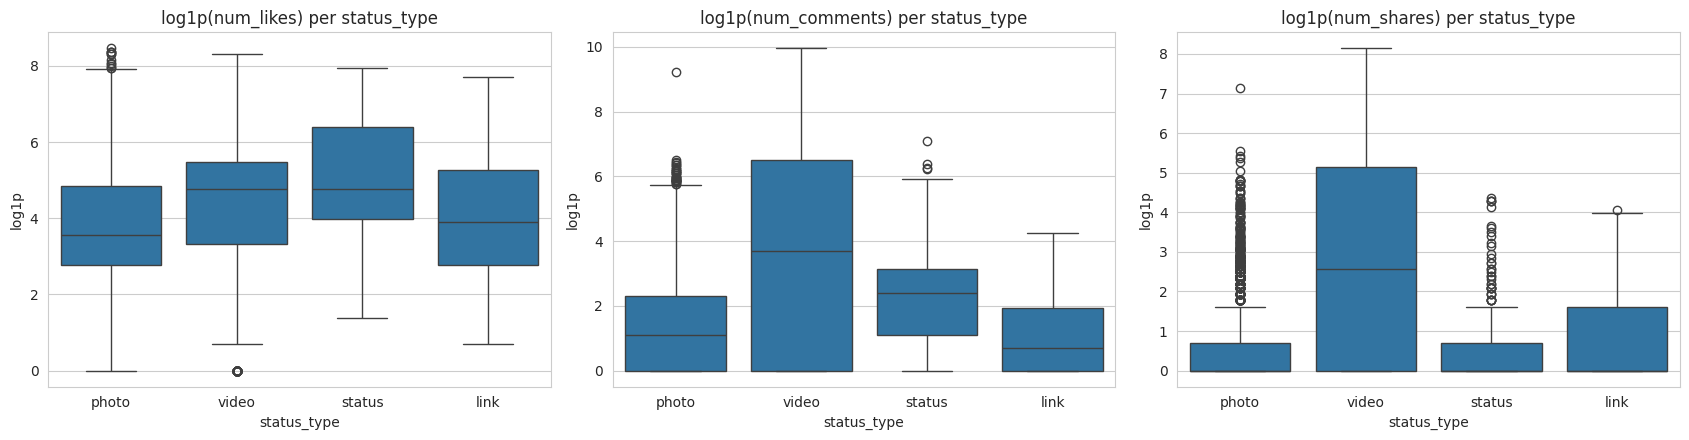

In [7]:
# EDA tambahan 1: sebaran interaksi (skala log1p) per status_type dan per tahun
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ['num_likes', 'num_comments', 'num_shares']):
    sns.boxplot(data=df.assign(v=np.log1p(df[c])), x='status_type', y='v', order=order, ax=ax)
    ax.set_title(f'log1p({c}) per status_type'); ax.set_ylabel('log1p')
plt.tight_layout()
plt.show()

# EDA tambahan 2: median interaksi per tahun dan proporsi nol komentar/share per status_type
display(df.groupby('year')[['num_likes', 'num_comments', 'num_shares', 'num_loves']].median().round(1))
display((df.groupby('status_type')[['num_comments', 'num_shares', 'num_loves']]
           .agg(lambda s: (s == 0).mean() * 100).round(1)
           .rename(columns=lambda c: f'% nol {c}').loc[order]))

**Temuan EDA:**
- Seluruh fitur hitungan sangat miring ke kanan (skewness 3.7 untuk `num_reactions` hingga >20 untuk `num_hahas`) dengan ekor panjang: median `num_comments` hanya 4, sedangkan maksimumnya 20.990. Skala antar fitur juga sangat berbeda (rata-rata `num_comments` ~224 vs `num_angrys` ~0,1).
- Proporsi nol tinggi: 55% posting tidak pernah di-share, dan reaksi `wow`, `haha`, `sad`, `angry` bernilai nol pada 75% sampai 94% posting.
- `num_reactions` dan `num_likes` berkorelasi 0,99 karena like mendominasi reaksi, dan `num_reactions` pada dasarnya adalah jumlah like + semua emoji (hampir seluruh baris cocok persis). `num_shares` berkorelasi tinggi dengan `num_loves` (0,82) dan `num_comments` (0,64).
- Reaksi emoji baru ada sejak 2016, sehingga 2012 sampai 2015 bernilai nol untuk seluruh kolom emoji. Setelah 2016 sekitar 54% sampai 68% posting memiliki emoji.
- Posting `video` memiliki median komentar dan share jauh lebih tinggi dibanding `photo`; `photo` mendominasi jumlah posting (61%).

# 2. Preprocessing

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.

# 1) Hapus kolom yang seluruhnya kosong (Column1 - Column4)
df_clean = df.drop(columns=kolom_kosong)
print('Kolom yang dihapus:', kolom_kosong)

# 2) Duplikat: status_id selalu unik, jadi duplikat harus dicari dengan MENGABAIKAN status_id
subset_cols = [c for c in df_clean.columns if c != 'status_id']
dup_all = df_clean[df_clean.duplicated(subset=subset_cols, keep=False)].sort_values(['status_published', 'status_id'])
print(f'\nBaris yang terlibat duplikasi: {len(dup_all)} (=> {df_clean.duplicated(subset=subset_cols).sum()} baris kelebihan)')
display(dup_all[['status_id', 'status_type', 'status_published', 'num_reactions',
                 'num_comments', 'num_shares', 'num_likes']].head(6))

n_sebelum = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=subset_cols, keep='first').reset_index(drop=True)
print(f'Jumlah baris: {n_sebelum} -> {len(df_clean)} (dihapus {n_sebelum - len(df_clean)})')

# 3) Missing value
print('\nTotal missing value setelah pembersihan:', int(df_clean.isna().sum().sum()))

# 4) Outlier ekstrem (batas atas IQR; hanya sebagai pemeriksaan)
rows = []
for c in ['num_likes', 'num_comments', 'num_shares', 'num_loves']:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    rows.append({'fitur': c, 'batas atas IQR': batas, '% di atas batas': (df_clean[c] > batas).mean() * 100,
                 'maksimum': df_clean[c].max()})
display(pd.DataFrame(rows).set_index('fitur').round(1))
print('Lima posting dengan komentar terbanyak:')
display(df_clean.nlargest(5, 'num_comments')[['status_type', 'status_published', 'num_likes', 'num_comments', 'num_shares']])

Kolom yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']

Baris yang terlibat duplikasi: 108 (=> 54 baris kelebihan)


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes
3762,3763,photo,2017-07-10 08:41:00,0,0,0,0
3763,3764,photo,2017-07-10 08:41:00,0,0,0,0
3738,3739,photo,2017-07-17 07:11:00,0,0,0,0
3739,3740,photo,2017-07-17 07:11:00,0,0,0,0
6220,6221,photo,2018-03-16 01:57:00,985,71,42,962
6271,6272,photo,2018-03-16 01:57:00,985,71,42,962


Jumlah baris: 7050 -> 6996 (dihapus 54)

Total missing value setelah pembersihan: 0


,batas atas IQR,% di atas batas,maksimum
fitur,,,
num_likes,429.5,10.8,4710
num_comments,55.6,19.5,20990
num_shares,10.0,19.8,3424
num_loves,7.5,18.6,657


Lima posting dengan komentar terbanyak:


,status_type,status_published,num_likes,num_comments,num_shares
498,video,2016-11-30 08:46:00,473,20990,154
480,video,2016-12-09 21:48:00,353,19013,161
6703,video,2017-09-25 10:35:00,525,17404,913
3246,video,2018-01-08 01:10:00,516,12003,856
6708,video,2017-09-21 08:01:00,540,10960,783


In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

# Metadata untuk interpretasi (TIDAK dipakai sebagai fitur clustering)
meta = df_clean[['status_type', 'status_published', 'year']].copy()

# Redundansi: num_reactions ~ jumlah like + semua emoji, sehingga dibuang
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
cocok = (df_clean['num_reactions'] == df_clean[['num_likes'] + emoji_cols].sum(axis=1)).mean() * 100
print(f'num_reactions = likes + emoji pada {cocok:.2f}% baris -> redundan, tidak dipakai')

print('\nProporsi nol tiap reaksi emoji (%):')
print((df_clean[emoji_cols] == 0).mean().mul(100).round(1).to_string())

# Gabungkan emoji yang sparse menjadi satu fitur
df_clean['num_emoji'] = df_clean[emoji_cols].sum(axis=1)
print(f'\nnum_emoji (gabungan 5 reaksi): {(df_clean["num_emoji"] == 0).mean()*100:.1f}% bernilai nol')

feature_cols = ['num_likes', 'num_comments', 'num_shares', 'num_emoji']
X = df_clean[feature_cols].copy()      # status_id, status_type, status_published, num_reactions, emoji individual tidak ikut
print('\nFitur clustering:', feature_cols, '| bentuk:', X.shape)

print('\nKorelasi antar fitur terpilih (data mentah):')
display(X.corr().round(2))

num_reactions = likes + emoji pada 99.87% baris -> redundan, tidak dipakai

Proporsi nol tiap reaksi emoji (%):
num_loves     60.4
num_wows      75.7
num_hahas     84.0
num_sads      91.5
num_angrys    94.0

num_emoji (gabungan 5 reaksi): 56.5% bernilai nol

Fitur clustering: ['num_likes', 'num_comments', 'num_shares', 'num_emoji'] | bentuk: (6996, 4)

Korelasi antar fitur terpilih (data mentah):


,num_likes,num_comments,num_shares,num_emoji
num_likes,1.00,0.11,0.18,0.23
num_comments,0.11,1.00,0.64,0.50
num_shares,0.18,0.64,1.00,0.81
num_emoji,0.23,0.50,0.81,1.00


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_comments`, `num_shares`, dan `num_emoji` (gabungan `num_loves` + `num_wows` + `num_hahas` + `num_sads` + `num_angrys`).

Alasan dan keputusan:
- `status_id` dibuang karena hanya penomoran baris, sedangkan `status_type` dan `status_published` disimpan terpisah (`meta`) hanya untuk interpretasi cluster.
- `num_reactions` **dibuang** karena redundan: nilainya sama dengan `num_likes` + seluruh reaksi emoji pada 99,87% baris (korelasi dengan `num_likes` 0,99). Jika dipertahankan, interaksi like akan terhitung dua kali dalam jarak.
- `num_wows`, `num_hahas`, `num_sads`, dan `num_angrys` sangat sparse (75,7% sampai 94,0% bernilai nol) dan nilainya kecil. Sebagai fitur sendiri-sendiri, kolom ini hampir tidak memberi informasi pemisah dan hanya menambah dimensi berisik. Kolom ini **digabung dengan `num_loves`** menjadi satu fitur `num_emoji` yang lebih padat (56,5% nol, sebagian besar karena posting sebelum 2016 memang belum punya emoji).
- `num_loves` tidak dipertahankan terpisah karena sudah menyumbang sebagian besar `num_emoji` dan berkorelasi tinggi dengan `num_shares` (0,82), sehingga bila dipisah akan memberi bobot ganda pada sinyal yang sama.
- Outlier ekstrem (misalnya posting video dengan 20.990 komentar) **tidak dihapus**. Posting tersebut adalah posting viral yang asli, bukan kesalahan data, dan justru merupakan kelompok yang ingin ditemukan. Pengaruh nilai ekstremnya diredam oleh transformasi `log1p`.
- Baris duplikat (54 baris, memiliki waktu terbit dan seluruh jumlah interaksi identik tetapi `status_id` berbeda) dihapus.

,skew sebelum,skew sesudah log1p,% nol
num_likes,3.93,-0.01,1.76
num_comments,8.99,1.05,30.25
num_shares,7.07,1.53,55.82
num_emoji,6.97,1.31,56.50


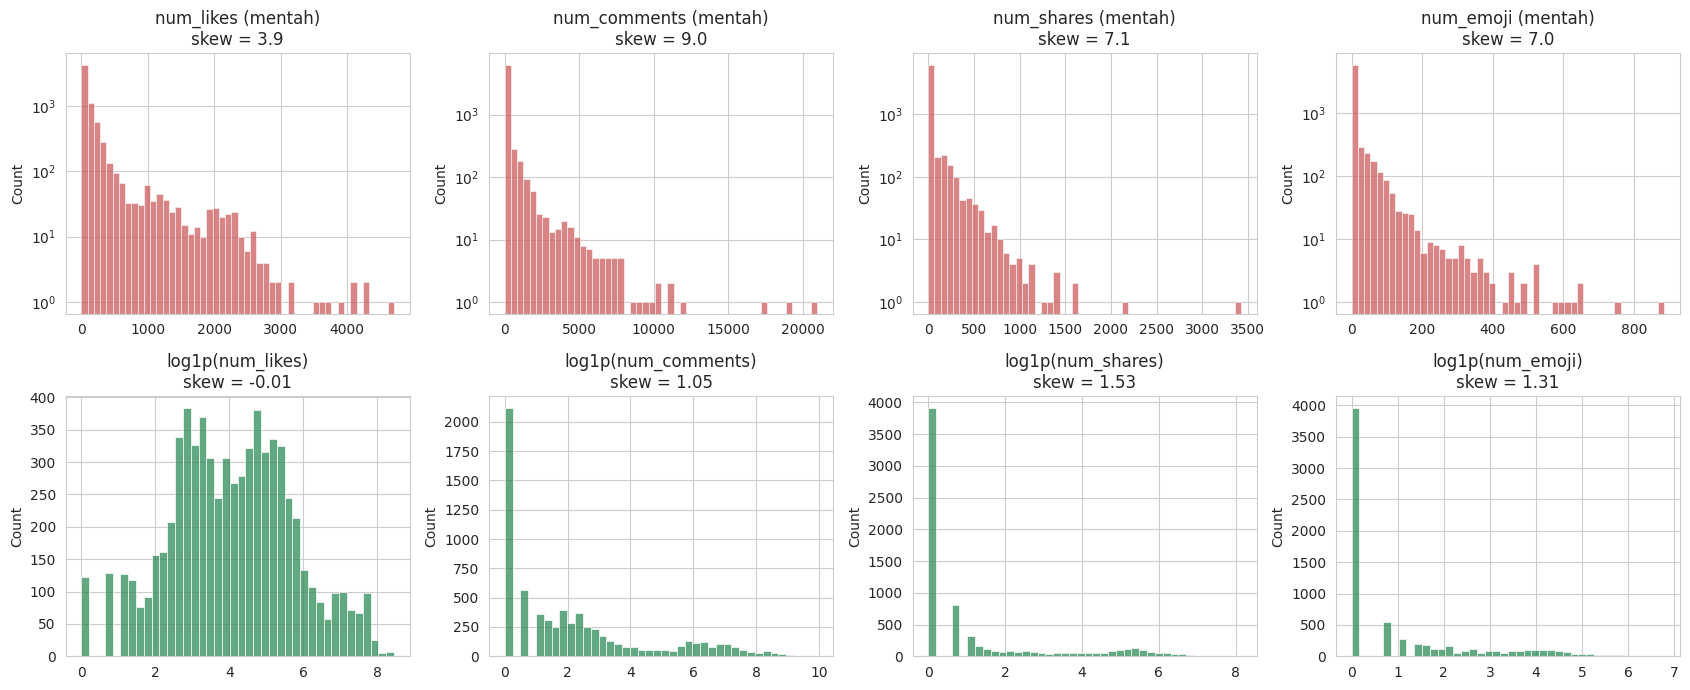

In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.

X_log = np.log1p(X)      # log(1 + x) aman untuk nilai nol

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, c in enumerate(feature_cols):
    sns.histplot(X[c], bins=50, ax=axes[0, j], color='indianred')
    axes[0, j].set_title(f'{c} (mentah)\nskew = {X[c].skew():.1f}')
    axes[0, j].set_yscale('log'); axes[0, j].set_xlabel('')
    sns.histplot(X_log[c], bins=40, ax=axes[1, j], color='seagreen')
    axes[1, j].set_title(f'log1p({c})\nskew = {X_log[c].skew():.2f}')
    axes[1, j].set_xlabel('')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'skew sebelum': X.skew(), 'skew sesudah log1p': X_log.skew(),
                      '% nol': (X == 0).mean() * 100}).round(2))

In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja

X_raw = X.values                                                   # mentah, tanpa transformasi dan scaling
X_raw_scaled = StandardScaler().fit_transform(X)                   # mentah + scaling saja
X_log_scaled = StandardScaler().fit_transform(X_log)               # log1p + scaling (dipakai sebagai data utama)

print('Bentuk X_raw / X_raw_scaled / X_log_scaled:', X_raw.shape, X_raw_scaled.shape, X_log_scaled.shape)

print('\nVarians per fitur pada X_raw (perhatikan perbedaan skala):')
var_raw = X.var()
display(pd.DataFrame({'varians': var_raw, '% dari total varians': var_raw / var_raw.sum() * 100}).round(1))

print('Rata-rata dan simpangan baku X_log_scaled (harus ~0 dan 1):')
print(pd.DataFrame(X_log_scaled, columns=feature_cols).agg(['mean', 'std']).round(3).to_string())

Bentuk X_raw / X_raw_scaled / X_log_scaled: (6996, 4) (6996, 4) (6996, 4)

Varians per fitur pada X_raw (perhatikan perbedaan skala):


,varians,% dari total varians
num_likes,193268.4,19.1
num_comments,797310.1,78.9
num_shares,17443.2,1.7
num_emoji,2299.6,0.2


Rata-rata dan simpangan baku X_log_scaled (harus ~0 dan 1):
      num_likes  num_comments  num_shares  num_emoji
mean       -0.0          -0.0         0.0       -0.0
std         1.0           1.0         1.0        1.0


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.

K0 = 3
datasets = {'X_raw': X_raw, 'X_raw_scaled': X_raw_scaled, 'X_log_scaled': X_log_scaled}

labels_31 = {}
for nama, data in datasets.items():
    km = KMeans(n_clusters=K0, random_state=RANDOM_STATE, n_init=10)
    labels_31[nama] = km.fit_predict(data)
    print(f'{nama:14s} selesai, inertia = {km.inertia_:,.1f}')

X_raw          selesai, inertia = 2,368,964,516.6
X_raw_scaled   selesai, inertia = 11,817.4
X_log_scaled   selesai, inertia = 6,779.8


In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.

rows = []
for nama, lab in labels_31.items():
    ukuran = np.bincount(lab)
    rows.append({
        'data': nama,
        'ukuran cluster (urut besar)': sorted(ukuran.tolist(), reverse=True),
        '% cluster terbesar': ukuran.max() / len(lab) * 100,
        'silhouette (ruang X_log_scaled)': silhouette_score(X_log_scaled, lab),
        'silhouette (ruang data sendiri)': silhouette_score(datasets[nama], lab),
    })
perbandingan_31 = pd.DataFrame(rows).set_index('data')
display(perbandingan_31.round(3))

# Kesepakatan pembagian cluster antar versi data (ARI: 1 = identik, 0 = acak)
print('Adjusted Rand Index antar versi data:')
print(f"  X_raw          vs X_log_scaled : {adjusted_rand_score(labels_31['X_raw'], labels_31['X_log_scaled']):.3f}")
print(f"  X_raw_scaled   vs X_log_scaled : {adjusted_rand_score(labels_31['X_raw_scaled'], labels_31['X_log_scaled']):.3f}")

# Median fitur asli per cluster pada X_raw: apakah cluster hanya memisahkan komentar/like ekstrem?
print('\nMedian fitur asli per cluster hasil K-Means pada X_raw:')
display(X.assign(cluster=labels_31['X_raw']).groupby('cluster').agg(['median']).droplevel(1, axis=1)
          .assign(n=np.bincount(labels_31['X_raw'])))

,ukuran cluster (urut besar),% cluster terbesar,silhouette (ruang X_log_scaled),silhouette (ruang data sendiri)
data,,,,
X_raw,"[6392, 467, 137]",91.366,0.273,0.789
X_raw_scaled,"[6277, 373, 346]",89.723,0.253,0.780
X_log_scaled,"[3607, 2258, 1131]",51.558,0.464,0.464


Adjusted Rand Index antar versi data:
  X_raw          vs X_log_scaled : 0.092
  X_raw_scaled   vs X_log_scaled : 0.128

Median fitur asli per cluster hasil K-Means pada X_raw:


,num_likes,num_comments,num_shares,num_emoji,n
cluster,,,,,
0,45.0,3.0,0.0,0.0,6392
1,307.0,4432.0,372.0,85.0,137
2,1463.0,25.0,3.0,0.0,467


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.

K_RANGE = list(range(2, 11))
inertias = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)
    inertias.append(km.inertia_)
    print(f'k = {k:2d}  inertia = {km.inertia_:,.1f}')

k =  2  inertia = 11,586.9
k =  3  inertia = 6,779.8
k =  4  inertia = 5,678.3
k =  5  inertia = 4,740.0
k =  6  inertia = 4,220.3
k =  7  inertia = 3,772.1
k =  8  inertia = 3,418.6
k =  9  inertia = 3,116.4
k = 10  inertia = 2,899.1


Elbow terdeteksi pada k = 4 | metode: jarak ke garis lurus (pengganti kneed)
Penurunan inertia (%) saat k naik: {3: np.float64(41.5), 4: np.float64(16.2), 5: np.float64(16.5), 6: np.float64(11.0), 7: np.float64(10.6), 8: np.float64(9.4), 9: np.float64(8.8), 10: np.float64(7.0)}


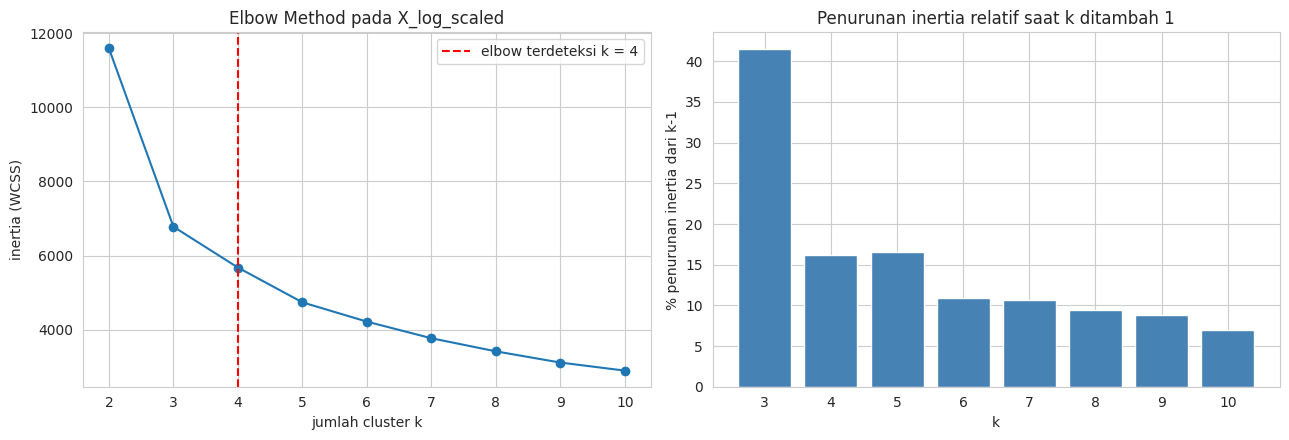

In [15]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

def cari_elbow(ks, nilai):
    """Fungsi pengganti kneed: titik dengan jarak terjauh ke garis lurus yang menghubungkan titik awal dan akhir kurva."""
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(nilai) - min(nilai)) / (max(nilai) - min(nilai))
    jarak = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0])
    return ks[int(np.argmax(jarak))]

if HAS_KNEED:
    k_elbow = KneeLocator(K_RANGE, inertias, curve='convex', direction='decreasing').elbow
    metode_elbow = 'kneed (KneeLocator)'
else:
    k_elbow = cari_elbow(K_RANGE, inertias)
    metode_elbow = 'jarak ke garis lurus (pengganti kneed)'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(K_RANGE, inertias, 'o-')
axes[0].axvline(k_elbow, color='red', ls='--', label=f'elbow terdeteksi k = {k_elbow}')
axes[0].set_xlabel('jumlah cluster k'); axes[0].set_ylabel('inertia (WCSS)')
axes[0].set_title('Elbow Method pada X_log_scaled'); axes[0].legend()

penurunan = -np.diff(inertias) / np.array(inertias[:-1]) * 100
axes[1].bar(K_RANGE[1:], penurunan, color='steelblue')
axes[1].set_xlabel('k'); axes[1].set_ylabel('% penurunan inertia dari k-1')
axes[1].set_title('Penurunan inertia relatif saat k ditambah 1')
plt.tight_layout()
plt.show()

print('Elbow terdeteksi pada k =', k_elbow, '| metode:', metode_elbow)
print('Penurunan inertia (%) saat k naik:', dict(zip(K_RANGE[1:], penurunan.round(1))))

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [16]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

silhouettes = {}
for k in K_RANGE:
    lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_log_scaled)
    silhouettes[k] = silhouette_score(X_log_scaled, lab)
    print(f'k = {k:2d}  silhouette = {silhouettes[k]:.4f}')

k =  2  silhouette = 0.5899
k =  3  silhouette = 0.4638
k =  4  silhouette = 0.3372
k =  5  silhouette = 0.3586
k =  6  silhouette = 0.3469
k =  7  silhouette = 0.3367
k =  8  silhouette = 0.3154
k =  9  silhouette = 0.3293
k = 10  silhouette = 0.3160


,inertia,silhouette
k,,
2,11586.902,0.590
3,6779.837,0.464
4,5678.251,0.337
5,4739.956,0.359
6,4220.276,0.347
7,3772.102,0.337
8,3418.566,0.315
9,3116.428,0.329
10,2899.055,0.316


Elbow: k = 4 | Silhouette terbaik: k = 2


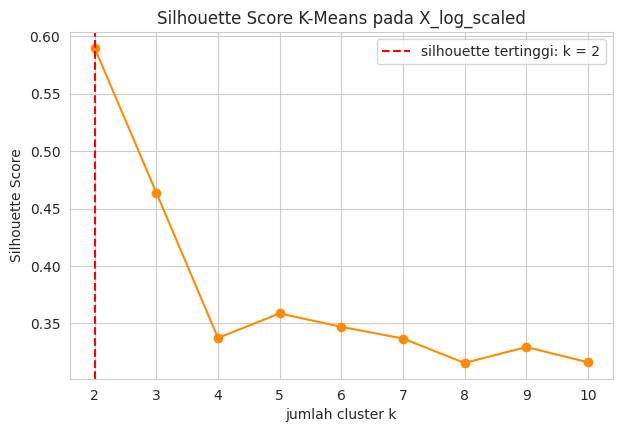

In [17]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.

k_sil = max(silhouettes, key=silhouettes.get)

plt.figure(figsize=(7, 4.5))
plt.plot(list(silhouettes.keys()), list(silhouettes.values()), 'o-', color='darkorange')
plt.axvline(k_sil, color='red', ls='--', label=f'silhouette tertinggi: k = {k_sil}')
plt.xlabel('jumlah cluster k'); plt.ylabel('Silhouette Score')
plt.title('Silhouette Score K-Means pada X_log_scaled'); plt.legend()
plt.show()

display(pd.DataFrame({'inertia': inertias, 'silhouette': list(silhouettes.values())}, index=pd.Index(K_RANGE, name='k')).round(3))
print(f'Elbow: k = {k_elbow} | Silhouette terbaik: k = {k_sil}')

**Pilihan k untuk K-Means: k = 3**

- **Silhouette** tertinggi ada pada k = 2 (0,590), lalu turun ke 0,464 pada k = 3, dan 0,337 pada k = 4. Untuk k = 4 sampai 10 nilainya berada di kisaran 0,31 sampai 0,36 tanpa puncak yang jelas.
- **Elbow**: penurunan inertia terbesar terjadi dari k = 2 ke k = 3 (41,5%), lalu hanya sekitar 16% pada k = 4 dan k = 5, dan di bawah 11% setelahnya. Deteksi otomatis (jarak ke garis lurus) menunjuk k = 4, tetapi selisih penurunan antara k = 4 dan k = 5 hampir sama (16,2% vs 16,5%), sehingga siku di k = 4 tidak tegas, sedangkan patahan di k = 3 jauh lebih jelas.
- Kedua metode tidak sepenuhnya sepakat (silhouette: 2, elbow otomatis: 4). Saya memilih **k = 3** sebagai titik temu: silhouette-nya masih tinggi (0,464, jauh di atas k >= 4), inertia sudah turun tajam, dan hasilnya dapat ditafsirkan. k = 2 hanya membagi data menjadi "sepi" dan "ramai", yang terlalu kasar untuk tujuan segmentasi. Sementara itu pada k >= 4 silhouette turun karena data tidak punya batas alami antar cluster, melainkan lebih mirip kontinum tingkat engagement.

## 3.4 Model K-Means Final

In [18]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

K_BEST = 3   # <- nilai k yang dipilih (lihat alasan pada cell markdown di atas)

def urutkan_label(labels, data=X_log_scaled):
    """Beri nomor ulang cluster: 0 = tingkat interaksi terendah ... k-1 = tertinggi (rata-rata skor gabungan fitur ter-scaling)."""
    skor = pd.Series(data.sum(axis=1)).groupby(labels).mean().sort_values()
    peta = {lama: baru for baru, lama in enumerate(skor.index)}
    return np.array([peta[l] for l in labels])

kmeans_final = KMeans(n_clusters=K_BEST, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)
labels_km = urutkan_label(kmeans_final.labels_)

print('Jumlah cluster:', K_BEST)
print('Ukuran tiap cluster:', dict(enumerate(np.bincount(labels_km))))
print(f'Silhouette = {silhouette_score(X_log_scaled, labels_km):.4f}')

Jumlah cluster: 3
Ukuran tiap cluster: {0: np.int64(3607), 1: np.int64(2258), 2: np.int64(1131)}
Silhouette = 0.4638


In [19]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.

def profil_cluster(labels, data=X):
    """Profil tiap cluster pada data ASLI: ukuran, median, dan rata-rata tiap fitur."""
    g = data.assign(cluster=labels).groupby('cluster')
    prof = pd.concat([
        pd.Series(np.bincount(labels), name='n_posting'),
        (pd.Series(np.bincount(labels)) / len(labels) * 100).rename('% data'),
        g.median().add_prefix('median_'),
        g.mean().add_prefix('mean_'),
    ], axis=1)
    prof.index.name = 'cluster'
    return prof.round(1)

profil_km = profil_cluster(labels_km)
display(profil_km)

# Pelengkap interpretasi: proporsi posting dengan emoji dan rentang tahun dominan per cluster
tambahan = meta.assign(cluster=labels_km, has_emoji=(df_clean['num_emoji'] > 0)).groupby('cluster').agg(
    pct_ada_emoji=('has_emoji', lambda s: s.mean() * 100),
    median_tahun=('year', 'median'))
display(tambahan.round(1))

,n_posting,% data,median_num_likes,median_num_comments,median_num_shares,median_num_emoji,mean_num_likes,mean_num_comments,mean_num_shares,mean_num_emoji
cluster,,,,,,,,,,
0,3607,51.6,18.0,0.0,0.0,0.0,22.2,2.1,0.5,0.2
1,2258,32.3,206.0,11.0,1.0,2.0,462.7,26.9,4.7,4.6
2,1131,16.2,170.0,722.0,178.0,57.0,304.5,1335.4,238.0,83.3


,pct_ada_emoji,median_tahun
cluster,,
0,15.3,2017.0
1,60.2,2016.0
2,100.0,2018.0


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [20]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.

Z = linkage(X_log_scaled, method='ward')
print('Bentuk linkage matrix:', Z.shape, '(n-1 penggabungan x 4 kolom)')
print('\nTinggi 10 penggabungan terakhir (dari yang paling akhir):')
print(np.round(Z[-10:, 2][::-1], 2))

Bentuk linkage matrix: (6995, 4) (n-1 penggabungan x 4 kolom)

Tinggi 10 penggabungan terakhir (dari yang paling akhir):
[175.13 103.7   48.41  42.31  37.54  27.48  27.38  21.13  20.25  19.44]


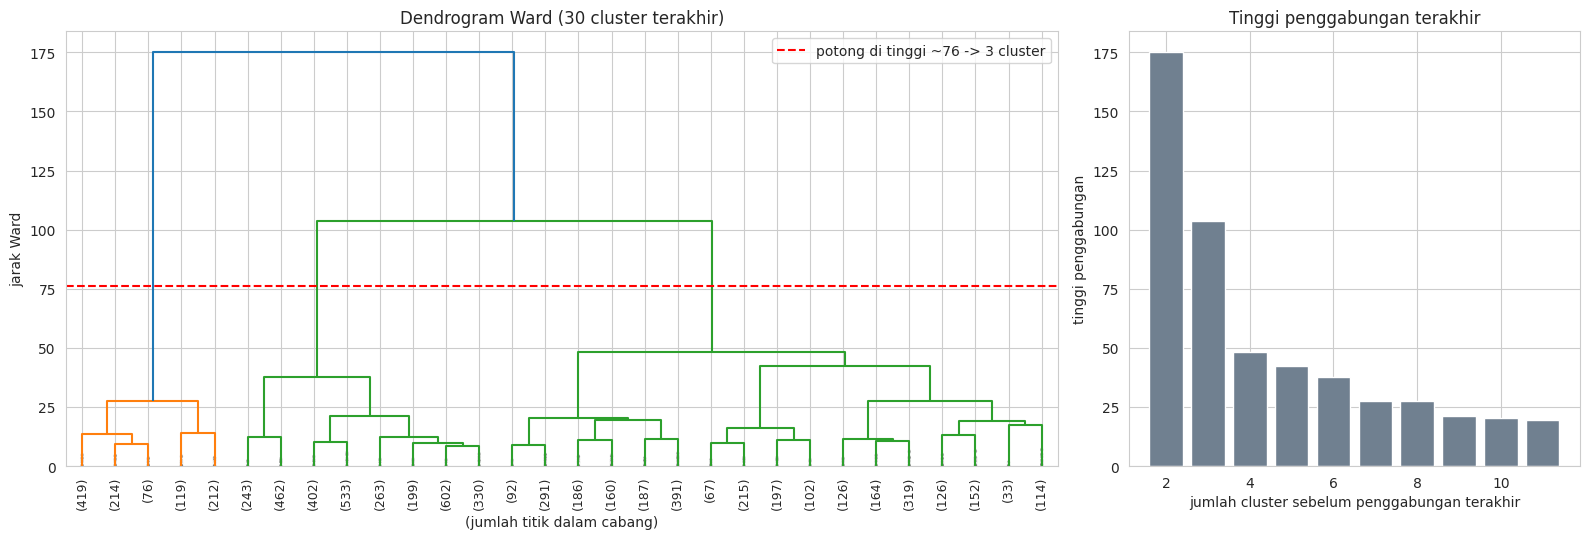

In [21]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.

# Ketinggian potong yang menghasilkan K_BEST cluster
tinggi_potong = (Z[-(K_BEST - 1), 2] + Z[-K_BEST, 2]) / 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, ax=axes[0])
axes[0].axhline(tinggi_potong, color='red', ls='--', label=f'potong di tinggi ~{tinggi_potong:.0f} -> {K_BEST} cluster')
axes[0].set_title('Dendrogram Ward (30 cluster terakhir)')
axes[0].set_xlabel('(jumlah titik dalam cabang)'); axes[0].set_ylabel('jarak Ward')
axes[0].legend()

n_tampil = 10
axes[1].bar(range(2, n_tampil + 2), Z[-n_tampil:, 2][::-1], color='slategray')
axes[1].set_xlabel('jumlah cluster sebelum penggabungan terakhir'); axes[1].set_ylabel('tinggi penggabungan')
axes[1].set_title('Tinggi penggabungan terakhir')
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [22]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.

linkages = ['ward', 'complete', 'average', 'single']
labels_hc = {}
for lk in linkages:
    labels_hc[lk] = AgglomerativeClustering(n_clusters=K_BEST, linkage=lk).fit_predict(X_log_scaled)
    print(f'linkage = {lk:9s} selesai -> ukuran cluster: {sorted(np.bincount(labels_hc[lk]).tolist(), reverse=True)}')

linkage = ward      selesai -> ukuran cluster: [3034, 2922, 1040]
linkage = complete  selesai -> ukuran cluster: [5775, 761, 460]
linkage = average   selesai -> ukuran cluster: [5764, 1197, 35]
linkage = single    selesai -> ukuran cluster: [6994, 1, 1]


In [23]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).

rows = []
for lk in linkages:
    lab = labels_hc[lk]
    ukuran = np.bincount(lab)
    rows.append({'linkage': lk,
                 'ukuran cluster (urut besar)': sorted(ukuran.tolist(), reverse=True),
                 '% cluster terbesar': ukuran.max() / len(lab) * 100,
                 'cluster terkecil': ukuran.min(),
                 'silhouette': silhouette_score(X_log_scaled, lab),
                 'davies-bouldin': davies_bouldin_score(X_log_scaled, lab),
                 'calinski-harabasz': calinski_harabasz_score(X_log_scaled, lab)})
tabel_linkage = pd.DataFrame(rows).set_index('linkage')
display(tabel_linkage.round(3))

# Pembanding: K-Means dengan k yang sama
print(f'Pembanding K-Means (k = {K_BEST}): silhouette = {silhouette_score(X_log_scaled, labels_km):.3f}')

,ukuran cluster (urut besar),% cluster terbesar,cluster terkecil,silhouette,davies-bouldin,calinski-harabasz
linkage,,,,,,
ward,"[3034, 2922, 1040]",43.368,1040,0.420,0.833,9959.188
complete,"[5775, 761, 460]",82.547,460,0.116,0.747,2560.558
average,"[5764, 1197, 35]",82.390,35,0.507,0.522,4856.535
single,"[6994, 1, 1]",99.971,1,0.314,0.485,3.467


Pembanding K-Means (k = 3): silhouette = 0.464


**Pilihan linkage untuk Hierarchical Clustering: ward**

Dengan jumlah cluster yang sama (k = 3), hasil keempat linkage sangat berbeda:
- **single**: ukuran cluster [6.994, 1, 1] (99,97% data masuk satu cluster) akibat efek *chaining*, sehingga hanya memisahkan dua titik pencilan. Silhouette 0,314 tampak lumayan, tetapi menyesatkan karena hampir seluruh data dianggap satu kelompok.
- **complete**: [5.775, 761, 460] dengan silhouette hanya 0,116, jadi cluster-nya saling tumpang tindih dan tidak seimbang.
- **average**: silhouette tertinggi (0,507) dan Davies-Bouldin rendah (0,522), namun salah satu cluster hanya berisi 35 posting (82,4% data di cluster terbesar). Nilai metriknya tinggi terutama karena cluster kecil berisi pencilan mudah dipisahkan, bukan karena segmentasi yang berguna.
- **ward**: satu-satunya yang menghasilkan cluster seimbang ([3.034, 2.922, 1.040]), dengan silhouette 0,420 dan Calinski-Harabasz tertinggi (9.959).

Ward dipilih karena meminimalkan penambahan varians dalam cluster (sejalan dengan tujuan K-Means) dan menghasilkan segmen yang bermakna, meskipun silhouette-nya bukan yang tertinggi.

## 4.3 Model Hierarchical Clustering Final

In [24]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

LINKAGE_BEST = 'ward'   # <- linkage yang dipilih (lihat alasan pada cell markdown di atas)

hc_final = AgglomerativeClustering(n_clusters=K_BEST, linkage=LINKAGE_BEST).fit(X_log_scaled)
labels_hc_final = urutkan_label(hc_final.labels_)

print('Linkage:', LINKAGE_BEST, '| jumlah cluster:', K_BEST)
print('Ukuran tiap cluster:', dict(enumerate(np.bincount(labels_hc_final))))
print(f'Silhouette = {silhouette_score(X_log_scaled, labels_hc_final):.4f}')

Linkage: ward | jumlah cluster: 3
Ukuran tiap cluster: {0: np.int64(3034), 1: np.int64(2922), 2: np.int64(1040)}
Silhouette = 0.4201


In [25]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.

profil_hc = profil_cluster(labels_hc_final)
display(profil_hc)

tambahan_hc = meta.assign(cluster=labels_hc_final, has_emoji=(df_clean['num_emoji'] > 0)).groupby('cluster').agg(
    pct_ada_emoji=('has_emoji', lambda s: s.mean() * 100),
    median_tahun=('year', 'median'))
display(tambahan_hc.round(1))

,n_posting,% data,median_num_likes,median_num_comments,median_num_shares,median_num_emoji,mean_num_likes,mean_num_comments,mean_num_shares,mean_num_emoji
cluster,,,,,,,,,,
0,3034,43.4,14.0,0.0,0.0,0.0,16.7,1.8,0.2,0.1
1,2922,41.8,150.0,9.0,1.0,1.0,386.8,29.4,5.3,4.5
2,1040,14.9,168.0,815.5,193.5,60.5,277.5,1430.2,255.4,88.2


,pct_ada_emoji,median_tahun
cluster,,
0,11.3,2017.0
1,56.8,2017.0
2,100.0,2018.0


# 5. Evaluasi Model

In [26]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.

def metrik(data, labels):
    return {'Silhouette (naik lebih baik)': silhouette_score(data, labels),
            'Davies-Bouldin (turun lebih baik)': davies_bouldin_score(data, labels),
            'Calinski-Harabasz (naik lebih baik)': calinski_harabasz_score(data, labels)}

tabel_eval = pd.DataFrame({f'K-Means (k={K_BEST})': metrik(X_log_scaled, labels_km),
                           f'Hierarchical ({LINKAGE_BEST}, k={K_BEST})': metrik(X_log_scaled, labels_hc_final)}).T
display(tabel_eval.round(3))

print('Adjusted Rand Index K-Means vs Hierarchical:', round(adjusted_rand_score(labels_km, labels_hc_final), 3))
print('\nTabel silang label K-Means (baris) vs Hierarchical (kolom):')
display(pd.crosstab(labels_km, labels_hc_final, rownames=['K-Means'], colnames=['Hierarchical']))

,Silhouette (naik lebih baik),Davies-Bouldin (turun lebih baik),Calinski-Harabasz (naik lebih baik)
K-Means (k=3),0.464,0.830,10935.461
"Hierarchical (ward, k=3)",0.420,0.833,9959.188


Adjusted Rand Index K-Means vs Hierarchical: 0.707

Tabel silang label K-Means (baris) vs Hierarchical (kolom):


Hierarchical,0,1,2
K-Means,,,
0,3031,576,0
1,3,2255,0
2,0,91,1040


Varians dijelaskan: PC1 = 75.9%, PC2 = 16.0%, total = 91.8%


,PC1,PC2
num_likes,0.40,0.89
num_comments,0.54,-0.05
num_shares,0.52,-0.35
num_emoji,0.52,-0.27


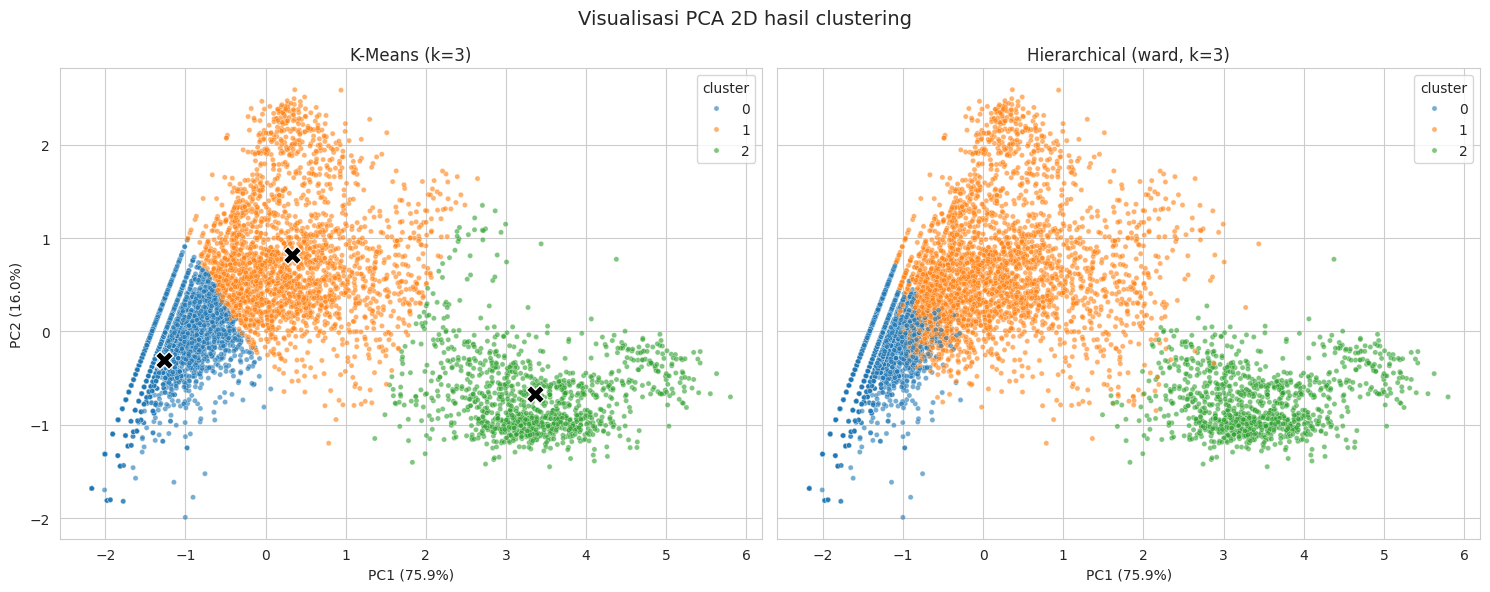

In [27]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
var_pca = pca.explained_variance_ratio_ * 100
print(f'Varians dijelaskan: PC1 = {var_pca[0]:.1f}%, PC2 = {var_pca[1]:.1f}%, total = {var_pca.sum():.1f}%')

# Posisi centroid K-Means pada ruang PCA
centroid_pca = pca.transform(pd.DataFrame(X_log_scaled).assign(c=labels_km).groupby('c').mean().values)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, lab, judul in zip(axes, [labels_km, labels_hc_final],
                          [f'K-Means (k={K_BEST})', f'Hierarchical ({LINKAGE_BEST}, k={K_BEST})']):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=lab, palette='tab10', s=14, alpha=0.6, ax=ax, legend='full')
    ax.set_title(judul); ax.set_xlabel(f'PC1 ({var_pca[0]:.1f}%)'); ax.set_ylabel(f'PC2 ({var_pca[1]:.1f}%)')
    ax.legend(title='cluster')
axes[0].scatter(centroid_pca[:, 0], centroid_pca[:, 1], c='black', marker='X', s=170, edgecolor='white', label='centroid')
plt.suptitle('Visualisasi PCA 2D hasil clustering', fontsize=14)
plt.tight_layout()
plt.show()

# Arti komponen: loading tiap fitur
display(pd.DataFrame(pca.components_.T, index=feature_cols, columns=['PC1', 'PC2']).round(2))

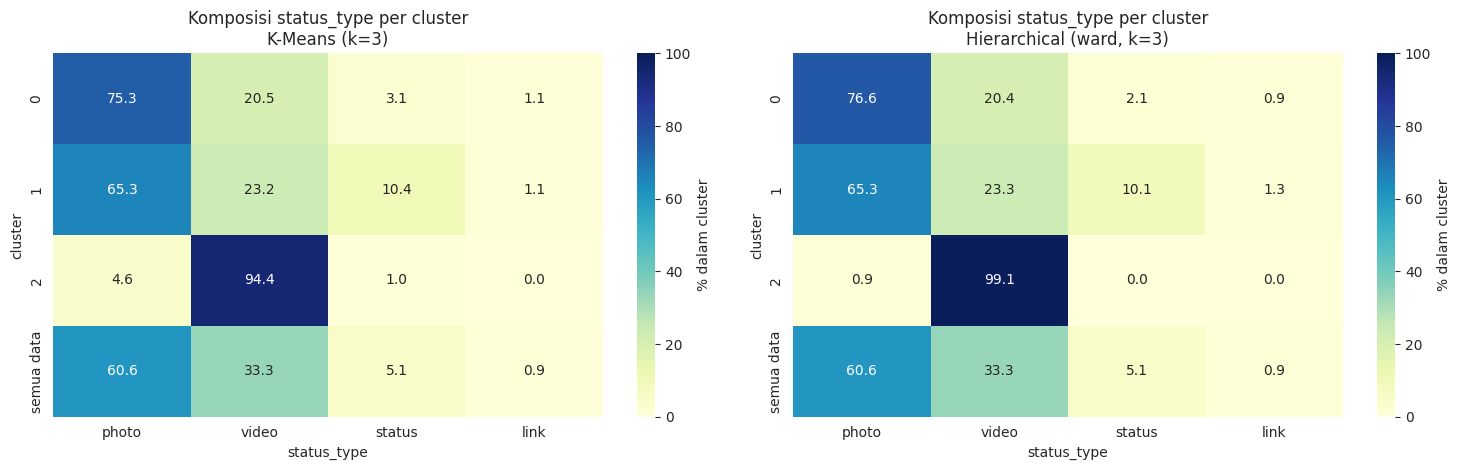

In [28]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.

dist_total = meta['status_type'].value_counts(normalize=True).mul(100)

def komposisi(labels):
    ct = pd.crosstab(labels, meta['status_type'], normalize='index') * 100
    ct.loc['semua data'] = dist_total
    return ct[['photo', 'video', 'status', 'link']]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, lab, judul in zip(axes, [labels_km, labels_hc_final],
                          [f'K-Means (k={K_BEST})', f'Hierarchical ({LINKAGE_BEST}, k={K_BEST})']):
    ct = komposisi(lab)
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=100, cbar_kws={'label': '% dalam cluster'}, ax=ax)
    ax.set_title(f'Komposisi status_type per cluster\n{judul}'); ax.set_ylabel('cluster'); ax.set_xlabel('status_type')
plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.


## Hasil Analisis

**1. Pengaruh transformasi log dan scaling (bagian 3.1).**
Pada `X_raw`, varians hampir seluruhnya didominasi `num_comments` (78,9%) dan `num_likes` (19,1%), sedangkan `num_shares` hanya 1,7% dan `num_emoji` 0,2%. Karena K-Means memakai jarak Euclidean, dua fitur besar itu menentukan seluruh pembagian cluster: K-Means pada data mentah menghasilkan cluster [6.392, 467, 137], di mana 91,4% posting masuk satu cluster, sementara dua cluster kecil hanya menangkap posting ekstrem (137 posting dengan median 4.432 komentar, dan 467 posting dengan median 1.463 like). Scaling saja (`X_raw_scaled`) menyamakan skala, tetapi distribusi masih sangat miring sehingga hasilnya hampir sama: [6.277, 373, 346] dan 89,7% di satu cluster. Baru setelah `log1p` + scaling, cluster menjadi seimbang ([3.607, 2.258, 1.131]). Ketika ketiganya diukur pada ruang yang sama (`X_log_scaled`), Silhouette hanya 0,273 (mentah) dan 0,253 (scaling saja), dibanding 0,464 untuk log + scaling. Kesepakatan antar versi juga rendah (ARI 0,092 dan 0,128), artinya pembagian cluster benar-benar berubah. Catatan penting: Silhouette pada ruang masing-masing (0,789 dan 0,780) terlihat jauh lebih tinggi, tetapi itu hanya karena titik ekstrem memisahkan diri secara jarak, bukan karena segmentasinya lebih baik, sehingga membandingkan skor di ruang yang berbeda tidak adil. Jadi, pada algoritma berbasis jarak, *scaling* diperlukan agar fitur berskala besar tidak mendominasi, dan *log* diperlukan agar outlier dan ekor panjang tidak menjadi satu-satunya hal yang dipelajari model.

**2. Penanganan kolom redundan dan sparse.**
`num_reactions` dibuang karena merupakan jumlah dari like dan emoji (cocok pada 99,87% baris), dan keempat reaksi emoji kecil (wow, haha, sad, angry) yang 75,7% sampai 94,0% nol digabung bersama `num_loves` menjadi `num_emoji`. Cara ini mengurangi dimensi, menghindari pembobotan ganda, dan mengubah beberapa kolom hampir-konstan menjadi satu sinyal yang cukup bervariasi. Konsekuensinya, kita tidak lagi bisa membedakan jenis emosi, dan karena emoji baru ada sejak 2016, fitur ini juga membawa sedikit informasi tentang periode posting (semua posting sebelum 2016 bernilai 0). Efek ini terlihat pada cluster 0 dan 1 yang masing-masing mengandung 26,2% dan 31,6% posting pra-2016, sedangkan cluster 2 seluruhnya (100%) pasca-2016.

**3. Jumlah cluster optimal.**
Silhouette menunjuk k = 2 (0,590), sedangkan Elbow (deteksi otomatis) menunjuk k = 4, dengan patahan penurunan inertia terbesar sebenarnya di k = 3 (41,5%). Keduanya tidak sepenuhnya sama. Saya memilih k = 3 karena merupakan kompromi: Silhouette masih 0,464, inertia sudah turun tajam, dan segmennya bermakna (k = 2 terlalu kasar, k >= 4 menurunkan Silhouette ke sekitar 0,34). Dendrogram Ward mendukung pilihan ini: tinggi penggabungan terakhir adalah 175,1 (2 ke 1) dan 103,7 (3 ke 2), lalu turun tajam ke 48,4, sehingga pemotongan di sekitar tinggi 76 menghasilkan 3 cluster.

**4. Perbandingan linkage.**
Pada k = 3: ward [3.034, 2.922, 1.040] dengan silhouette 0,420; complete [5.775, 761, 460] dengan 0,116; average [5.764, 1.197, 35] dengan 0,507; single [6.994, 1, 1] dengan 0,314. Ward paling baik karena satu-satunya yang seimbang dan memiliki Calinski-Harabasz tertinggi (9.959). Average memang memiliki silhouette tertinggi, tetapi salah satu clusternya hanya berisi 35 posting sehingga kurang berguna. Single linkage menghasilkan karakter khas *chaining*: karena hanya melihat jarak terdekat antar titik, data yang membentuk kontinum akan "merantai" menjadi satu cluster raksasa (99,97% data), dan dua cluster lainnya hanya berisi satu titik pencilan masing-masing. Skor Silhouette-nya (0,314) menipu karena tidak mencerminkan segmentasi yang berarti.

**5. K-Means vs Hierarchical.**
K-Means (k = 3): Silhouette 0,464, Davies-Bouldin 0,830, Calinski-Harabasz 10.935. Hierarchical Ward (k = 3): 0,420, 0,833, dan 9.959. K-Means sedikit lebih baik pada Silhouette dan Calinski-Harabasz, sedangkan Davies-Bouldin hampir sama (0,830 vs 0,833), jadi perbedaannya kecil. Pembagian keduanya juga mirip: ARI 0,707 dan sekitar 90,4% posting (6.326 dari 6.996) berada pada cluster yang setara. Pada visualisasi PCA (PC1 75,9% + PC2 16,0% = 91,8% varians), pola kedua metode juga sama: cluster 2 terpisah jelas di kanan, sedangkan cluster 0 dan 1 berbatasan langsung tanpa celah. Perbedaan utamanya ada di batas cluster 0 dan 1: Ward menempatkan 576 posting yang oleh K-Means masuk cluster 0 ke cluster 1, sehingga cluster 0 Ward lebih kecil (43,4% vs 51,6%) dan cluster 1 lebih besar (41,8% vs 32,3%). Kemiripan ini wajar karena keduanya sama-sama meminimalkan varians dalam cluster (Ward secara hierarkis, K-Means secara iteratif), dan bentuk data memang berupa kontinum dengan satu kelompok yang jelas terpisah.

**6. Karakteristik dan julukan cluster (K-Means, data asli).**
- **Cluster 0, "Posting Sepi" (3.607 posting, 51,6%)**: median 18 like, 0 komentar, 0 share, 0 emoji; hanya 15,3% yang memiliki emoji. Dominan foto (75,3%).
- **Cluster 1, "Disukai tapi Sepi Diskusi" (2.258 posting, 32,3%)**: median 206 like, hanya 11 komentar dan 1 share; 60,2% punya emoji. Mayoritas foto (65,3%) dan memiliki porsi `status` tertinggi (10,4%). Like-nya tinggi (rata-rata 462,7, bahkan lebih tinggi dari cluster 2), tetapi hampir tanpa percakapan atau penyebaran.
- **Cluster 2, "Video Viral dan Ramai Diskusi" (1.131 posting, 16,2%)**: median 722 komentar, 178 share, dan 57 emoji; 100% punya emoji dan 94,4% adalah video. Median like-nya (170) tidak lebih tinggi dari cluster 1, jadi yang membedakan cluster ini adalah komentar, share, dan emoji, bukan like.
Profil Hierarchical Ward serupa (Posting Sepi 3.034, Disukai tapi Sepi Diskusi 2.922, Video Viral 1.040 dengan 99,1% video). Satu catatan: `status_type` tidak dipakai sebagai fitur, tetapi cluster 2 hampir seluruhnya video, artinya perilaku engagement memang berbeda menurut tipe posting.

**7. Kelebihan dan kekurangan.**
- **K-Means**: kelebihan: cepat dan hemat memori (waktu kira-kira linear terhadap jumlah data, memori O(n x d)), mudah diskalakan ke data besar, dan menghasilkan centroid yang mudah diinterpretasi. Kekurangan: k harus ditentukan di awal (di sini Elbow dan Silhouette tidak sepakat), asumsi cluster berbentuk bulat dengan ukuran mirip, sensitif terhadap outlier, skala fitur, dan inisialisasi (perlu `n_init`).
- **Hierarchical (Agglomerative)**: kelebihan: tidak perlu menentukan k di awal (cukup memotong dendrogram, yang di sini memberi petunjuk jelas k = 3), deterministik, dan memperlihatkan struktur bersarang antar cluster. Kekurangan: butuh matriks jarak berukuran n x n sehingga memori dan waktu kira-kira kuadratik, sulit untuk data sangat besar (7.000 baris masih ringan, tetapi ratusan ribu baris tidak), penggabungan tidak bisa dibatalkan, dan hasilnya sangat bergantung pada linkage (single menghasilkan cluster tidak berguna, complete tumpang tindih).

**Keterbatasan.** Silhouette 0,46 menunjukkan struktur cluster yang sedang, bukan terpisah tegas, dan scatter PCA memperlihatkan bahwa cluster 0 dan 1 berbatasan langsung. Segmentasi ini lebih tepat dibaca sebagai tingkat engagement bertahap daripada kelompok alami yang tegas.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.


## Kesimpulan

1. Data engagement Facebook sangat miring dengan ekor panjang, banyak nilai nol, dan fitur yang redundan. Tanpa `log1p` dan scaling, K-Means hanya mengisolasi posting ekstrem (91,4% data jatuh ke satu cluster). Dengan `log1p` dan scaling pada empat fitur terpilih (`num_likes`, `num_comments`, `num_shares`, `num_emoji`), cluster menjadi seimbang dan dapat ditafsirkan.
2. Jumlah cluster yang dipilih adalah k = 3 (Silhouette k = 2 tertinggi 0,590, Elbow otomatis k = 4, patahan terbesar inertia di k = 3, dan dendrogram Ward mendukung 3 cluster).
3. Tiga segmen yang ditemukan: **Posting Sepi** (51,6%), **Disukai tapi Sepi Diskusi** (32,3%), dan **Video Viral dan Ramai Diskusi** (16,2%, 94,4% video).
4. Pada Hierarchical Clustering, **Ward** adalah linkage terbaik karena menghasilkan cluster seimbang; single linkage mengalami chaining ([6.994, 1, 1]), complete tumpang tindih (Silhouette 0,116), dan average menyisakan cluster berisi hanya 35 posting.
5. K-Means (Silhouette 0,464, DB 0,830, CH 10.935) sedikit lebih baik daripada Ward (0,420, 0,833, 9.959), tetapi keduanya sangat mirip (ARI 0,707; sekitar 90% posting sama). K-Means lebih efisien untuk data besar, sedangkan Hierarchical memberi gambaran struktur lewat dendrogram.

**Saran:**
- Lakukan clustering terpisah untuk periode sebelum dan sesudah 2016, karena reaksi emoji baru tersedia sejak 2016 dan fitur `num_emoji` kini ikut membawa informasi periode.
- Tambahkan fitur waktu (jam atau hari posting) dan status_type, serta pertimbangkan clustering per penjual bila identitas penjual tersedia.
- Coba algoritma lain seperti Gaussian Mixture Model (cluster yang saling tumpang tindih) atau DBSCAN (untuk mendeteksi posting viral sebagai pencilan), serta variasi `n_init` dan `init` pada K-Means.
- Uji stabilitas (misalnya beberapa `random_state` atau bootstrap) dan pertimbangkan reduksi dimensi sebelum clustering bila jumlah fitur bertambah.